# 04 · Aşama 4 — Seçici tespit ve risk–kapsama analizi
Tanımlar (hata = saldırının NORMAL kararı alması veya normal örneğin ANOMALY kararı alması):
* **Kapsama (coverage)** = otomatik karar verilen pay (NORMAL veya ANOMALY)
* **Çekimser kalma oranı (abstention)** = UNCERTAIN payı (normal ve saldırı için ayrıca raporlanır)
* **Seçici risk (selective risk)** = otomatik kararlardaki hata oranı
* **Görülmemiş saldırı recall** = ANOMALY kararı alan görülmemiş saldırılar; **ertelenen** = UNCERTAIN alanlar
* Saldırı yaygınlığına göre yeniden ağırlıklandırma (π ∈ {0,001; 0,01; 0,1}) test kümesindeki temel oran etkisini kaldırır.

Önceden kaydedilmiş uç noktalar: **E2** — konformal bant, *eşleştirilmiş kapsama*da güçlü alternatiflerden
(B3 sezgisel bant, IF bandı, gizil skor bandı; rastgele çekimserlik yalnızca alt sınır kontrolüdür) daha iyi mi?
**E3** — görülmemiş saldırı ailelerinin aile bazında tespiti ve ertelenmesi.

In [1]:
# ---- Kurulum (her defterde aynı): Drive'ı bağla, ortak kodu içe aktar ----
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
PROJECT_DIR = os.environ.get("TRUSTIDS_PROJECT", "/content/drive/MyDrive/TrustFed-TinyIDS-Final")
QUICK = os.environ.get("TRUSTIDS_QUICK", "0") == "1"   # hızlı mod YALNIZCA kodu test etmek içindir
# Devam modu: Colab oturumu kapanırsa, Drive'a kaydedilmiş tohumlar/adımlar atlanır ve kalan yerden devam edilir.
# Her şeyi baştan hesaplamak için: os.environ["TRUSTIDS_RESUME"] = "0"
RESUME = os.environ.get("TRUSTIDS_RESUME", "1") == "1"
sys.path.insert(0, PROJECT_DIR)

from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from trustids.config import Config
from trustids import utils

# Veri kümesi seçimi: varsayılan TON_IoT; ikinci veri kümesi için TRUSTIDS_CONFIG=edge_iiotset.json
CONFIG_NAME = os.environ.get("TRUSTIDS_CONFIG", "default.json")
CFG_PATH = Path(PROJECT_DIR) / "configs" / CONFIG_NAME
if CONFIG_NAME != "default.json" and not CFG_PATH.exists():
    raise FileNotFoundError(f"{CFG_PATH} bulunamadı: configs/ klasörünü de Drive'a yükleyin.")
cfg = Config.load(CFG_PATH) if CFG_PATH.exists() else Config(project_dir=PROJECT_DIR)
cfg.project_dir = PROJECT_DIR
if QUICK:
    cfg.train_seeds, cfg.validity_resplits, cfg.epochs = cfg.train_seeds[:2], 30, 15
    cfg.random_control_repeats, cfg.bootstrap_repeats = 10, 200
    cfg.lofo_seeds, cfg.fl_orig_rounds = cfg.lofo_seeds[:2], 3
    cfg.resolution_cal_windows, cfg.resolution_eval_windows = 600, 600
cfg.check()
ART = cfg.artifacts
FIG = Path(PROJECT_DIR) / cfg.figures_dir; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Proje klasörü:", PROJECT_DIR, "| hızlı mod:", QUICK, "| devam modu:", RESUME)
print("Drive'da kayıtlı ilerleme:", utils.progress(cfg))

Mounted at /content/drive
Proje klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final | hızlı mod: False | devam modu: True
Drive'da kayıtlı ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': False}


In [2]:
from trustids import data as D, conformal as C, metrics as MT, evaluation as E, plotting as PL
P = D.load_prepared(ART / "prepared")
SEEDS = E.available_seeds(cfg); GROUPS = E.family_groups(cfg)
def decisions(seed):
    z = np.load(ART / "decisions" / f"seed{seed}.npz"); return {k: z[k] for k in z.files}
RUN = utils.new_run_dir(Path(PROJECT_DIR) / cfg.runs_dir, "midterm_phase4")
PREP_REP = utils.load_json(ART / "prepared" / "prepare_report.json")
if not PREP_REP["calibration_rule"]["rule_satisfied"]:          # önceden kaydedilmiş n_cal kuralı
    cfg.alpha = PREP_REP["calibration_rule"]["alpha_effective"]
EXCLUDE_MACRO = () if PREP_REP.get("mitm_in_macro_average", True) else ("mitm",)   # mitm yedek kuralı
utils.save_json(utils.environment_info(), RUN / "environment.json")
print("alpha =", cfg.alpha, "| makro ortalamadan çıkarılan:", EXCLUDE_MACRO)
print("sonuç klasörü:", RUN)

alpha = 0.01 | makro ortalamadan çıkarılan: ()
sonuç klasörü: /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261111-042106_midterm_phase4


## Genel seçici metrikler (tohum 0), yaygınlığa göre yeniden ağırlıklandırma ile

In [3]:
S0, D0 = E.load_scores(cfg, SEEDS[0]), decisions(SEEDS[0])
rows = []
for model in E.MODELS:
    ev = E.eval_set(P, S0, model)
    for pi in [None] + cfg.prevalence_grid:
        r = MT.selective_metrics(ev["y_attack"], D0[f"{model}__d"], pi)
        rows.append({"model": model, "yaygınlık": "test kümesi" if pi is None else pi, **r})
OVR = pd.DataFrame(rows); OVR.to_csv(RUN / "overall_selective_seed0.csv", index=False); OVR.round(4)

,model,yaygınlık,coverage,abstention,selective_risk,benign_anomaly_rate,benign_uncertain_rate,attack_anomaly_rate,attack_uncertain_rate,attack_missed_rate,precision_auto
0,ae,test kümesi,0.7494,0.2506,0.5553,0.0075,0.0400,0.2713,0.2717,0.4571,0.9973
1,ae,0.001,0.9598,0.0402,0.0082,0.0075,0.0400,0.2713,0.2717,0.4571,0.0351
2,ae,0.01,0.9577,0.0423,0.0125,0.0075,0.0400,0.2713,0.2717,0.4571,0.2685
3,ae,0.1,0.9368,0.0632,0.0560,0.0075,0.0400,0.2713,0.2717,0.4571,0.8015
4,iforest,test kümesi,0.9891,0.0109,0.9129,0.0161,0.0361,0.0000,0.0084,0.9916,0.0000
5,iforest,0.001,0.9639,0.0361,0.0177,0.0161,0.0361,0.0000,0.0084,0.9916,0.0000
6,iforest,0.01,0.9641,0.0359,0.0268,0.0161,0.0361,0.0000,0.0084,0.9916,0.0000
7,iforest,0.1,0.9666,0.0334,0.1176,0.0161,0.0361,0.0000,0.0084,0.9916,0.0000
8,latent,test kümesi,0.8823,0.1177,0.8724,0.0137,0.0415,0.0293,0.1253,0.8454,0.9553
9,latent,0.001,0.9584,0.0416,0.0152,0.0137,0.0415,0.0293,0.1253,0.8454,0.0021


## Profesörün metrikleri: normal / bilinen / görülmemiş ayrı ayrı (tohum 0, AE)

In [4]:
ev = E.eval_set(P, S0, "ae"); d = D0["ae__d"]; p = D0["ae__p"]
rows = []
for part, name in [("dev_test", "bilinen"), ("heldout_test", "görülmemiş")]:
    m = (ev["split"] == "benign_test") | (ev["split"] == part)
    y = ev["y_attack"][m]
    rows.append({"saldırılar": name, **MT.binary_metrics(y, ev["scores"][m], d[m] == C.ANOMALY),
                 **MT.selective_metrics(y, d[m])})
PROF = pd.DataFrame(rows); PROF.to_csv(RUN / "professor_metrics_seed0.csv", index=False); PROF.round(4)

,saldırılar,precision,recall,f1,fpr,pr_auc,roc_auc,coverage,abstention,selective_risk,benign_anomaly_rate,benign_uncertain_rate,attack_anomaly_rate,attack_uncertain_rate,attack_missed_rate,precision_auto
0,bilinen,0.9944,0.1843,0.3110,0.0075,0.9742,0.8701,0.7860,0.2140,0.6455,0.0075,0.04,0.1843,0.2383,0.5773,0.9944
1,görülmemiş,0.9947,0.4892,0.6558,0.0075,0.9871,0.9708,0.7267,0.2733,0.1612,0.0075,0.04,0.4892,0.3552,0.1557,0.9947


## E2 — Konformal bant, eşleştirilmiş kapsamada alternatiflerden daha mı iyi? (tüm tohumlar)
Alternatif yöntemlere referans kuralla **aynı sayıda** UNCERTAIN kararı verdirilir (etiket kullanılmaz). `delta_sr > 0` konformal AE bandının seçici riskinin **daha düşük** olduğu anlamına gelir; fark yanlış alarm ve kaçırma bileşenlerine ayrıştırılır.

In [5]:
rows = []
for seed in SEEDS:
    S, Dd = E.load_scores(cfg, seed), decisions(seed)
    ev = E.eval_set(P, S, "ae"); y = ev["y_attack"]; d_ref = Dd["ae__d"]
    h = C.heuristic_thresholds(ev["train"], cfg.heuristic_k[0], cfg.heuristic_k[1])
    alts = {"B3 sezgisel bant (eğitim hataları)": (ev["scores"], h["tau_H"])}
    for model, label in [("iforest", "B1 IF konformal bandı"), ("latent", "B5 gizil skor bandı")]:
        e2 = E.eval_set(P, S, model)
        alts[label] = (e2["scores"], C.thresholds(e2["cal"], cfg.alpha, cfg.beta)["tau_H"])
    for label, (s_alt, tauH) in alts.items():
        for pi in [None, 0.01]:
            r = MT.matched_coverage_comparison(y, d_ref, s_alt, tauH, pi)
            rows.append({"seed": seed, "comparison": label, "prevalence": "test kümesi" if pi is None else pi, **r})
    rc = MT.random_abstention_control(y, d_ref, cfg.random_control_repeats, seed)
    rows.append({"seed": seed, "comparison": "rastgele çekimserlik (alt sınır)", "prevalence": "test kümesi",
                 "sr_ref": rc["real_selective_risk"], "sr_alt": rc["random_mean"], "delta_sr": rc["delta"]})
E2 = pd.DataFrame(rows); E2.to_csv(RUN / "E2_matched_coverage.csv", index=False)
cols = ["abstain_ref", "abstain_alt", "sr_ref", "sr_alt", "delta_sr", "delta_false_alarm_part", "delta_miss_part"]
E2.groupby(["comparison", "prevalence"])[[c for c in cols if c in E2]].mean().round(5)

abstain_ref  abstain_alt   sr_ref   sr_alt  delta_sr  delta_false_alarm_part  delta_miss_part
comparison                         prevalence                                                                                                
B1 IF konformal bandı              0.01              9785.3        795.8  0.01227  0.02363   0.01136                 0.00593          0.00543
                                   test kümesi       9785.3       9752.2  0.57267  0.89338   0.32071                 0.00071          0.32000
B3 sezgisel bant (eğitim hataları) 0.01              9785.3       4981.6  0.01227  0.02333   0.01107                 0.01112         -0.00006
                                   test kümesi       9785.3       9785.3  0.57267  0.40169  -0.17097                 0.00135         -0.17232
B5 gizil skor bandı                0.01              9785.3       1981.5  0.01227  0.02024   0.00797                 0.00297          0.00500
                                   test kümesi       9785.3       9785.3  0.57267  0.88667   0.31400                 0.00036          0.31365
rastgele çekimserlik (alt sınır)   test kümesi          NaN          NaN  0.57267  0.68167   0.10900                     NaN              NaN

### E2 istatistikleri — iki yaygınlık düzeyinde
* **test kümesi** (önceden kaydedilmiş birincil analiz; eşleştirme etiketsiz, UNCERTAIN *sayısı* üzerinden);
* **π = 0,01** (keşifsel; eşleştirme yaygınlık ağırlıklı UNCERTAIN *kütlesi* üzerinden — etiket kullanır, yalnızca analiz amaçlıdır).

Not: 10 tohumla Wilcoxon testinin alabileceği en küçük iki yönlü p-değeri 2/1024 ≈ 0,002'dir; asıl kanıt
bootstrap güven aralıklarıdır. **Bu aralıklar ve testler yalnızca eğitim tohumu değişkenliğini ölçer** (tek, sabit bir
veri bölmesi üzerinde); test örneklerinin örnekleme belirsizliğini içermez.

In [6]:
stats_rows = []
for prev, sub in E2.groupby("prevalence"):
    for comp, g in sub.groupby("comparison"):
        lo, hi = MT.bootstrap_ci(g["delta_sr"].to_numpy(), cfg.bootstrap_repeats, 0)
        stats_rows.append({"prevalence": prev, "comparison": comp, "mean_delta_sr": g["delta_sr"].mean(),
                           "ci_low": lo, "ci_high": hi, "seeds": len(g)})
ST = pd.DataFrame(stats_rows)
if len(SEEDS) >= 5:
    W = pd.concat([MT.paired_wilcoxon_holm(sub.assign(zero=0.0), "delta_sr", "zero", "comparison").assign(prevalence=prev)
                   for prev, sub in E2.groupby("prevalence")])
    ST = ST.merge(W[["prevalence", "comparison", "p_raw", "p_holm"]], on=["prevalence", "comparison"])
ST.to_csv(RUN / "E2_statistics.csv", index=False); ST.round(5)

,prevalence,comparison,mean_delta_sr,ci_low,ci_high,seeds,p_raw,p_holm
0,0.01,B1 IF konformal bandı,0.01136,0.01057,0.01228,10,0.00195,0.00586
1,0.01,B3 sezgisel bant (eğitim hataları),0.01107,0.00920,0.01332,10,0.00195,0.00586
2,0.01,B5 gizil skor bandı,0.00797,0.00699,0.00916,10,0.00195,0.00586
3,test kümesi,B1 IF konformal bandı,0.32071,0.29596,0.33817,10,0.00195,0.00781
4,test kümesi,B3 sezgisel bant (eğitim hataları),-0.17097,-0.20339,-0.13402,10,0.00195,0.00781
5,test kümesi,B5 gizil skor bandı,0.31400,0.29803,0.32614,10,0.00195,0.00781
6,test kümesi,rastgele çekimserlik (alt sınır),0.10900,0.10637,0.11099,10,0.00195,0.00781


### B3 sezgisel eşiğinin gerçekleşen yanlış alarm oranı (10 tohum)
μ + 3σ kuralı Gauss varsayımı altında yaklaşık %0,13 yanlış alarm *vaat eder*; ancak eğitim hatalarından
hesaplandığı için gerçek normal testte bu oran kontrol edilmez. Konformal kuralın oranı ise α ile sınırlıdır.

In [7]:
rows = []
for seed in SEEDS:
    S, Dd = E.load_scores(cfg, seed), decisions(seed)
    ev = E.eval_set(P, S, "ae"); b = ~ev["y_attack"]
    h = C.heuristic_thresholds(ev["train"], cfg.heuristic_k[0], cfg.heuristic_k[1])
    rows.append({"tohum": seed, "B3_normal_ANOMALY": float(np.mean(ev["scores"][b] > h["tau_H"])),
                 "konformal_normal_ANOMALY": float(np.mean(Dd["ae__d"][b] == C.ANOMALY))})
B3F = pd.DataFrame(rows)
for col in ["B3_normal_ANOMALY", "konformal_normal_ANOMALY"]:
    lo, hi = MT.bootstrap_ci(B3F[col].to_numpy(), cfg.bootstrap_repeats, 0)
    print(f"{col}: ortalama {B3F[col].mean():.4f}  (%95 GA {lo:.4f}–{hi:.4f}) | Gauss 3σ nominal = 0.00135 | α = {cfg.alpha}")
B3F.to_csv(RUN / "B3_false_alarm_10seeds.csv", index=False)

B3_normal_ANOMALY: ortalama 0.0179  (%95 GA 0.0163–0.0201) | Gauss 3σ nominal = 0.00135 | α = 0.01
konformal_normal_ANOMALY: ortalama 0.0072  (%95 GA 0.0066–0.0076) | Gauss 3σ nominal = 0.00135 | α = 0.01


## UNCERTAIN bandı gerçekte ne kazandırıyor? — katmanlama (10 tohum)
Üç yönlü kuralda ANOMALY ∪ UNCERTAIN birleşimi, **α+β düzeyindeki ikili kuralla aynıdır**; yani işaretlenen toplam
pay yapı gereği aynıdır. Kazanç, işaretlenen kümenin **anında alarm** ve **inceleme** katmanlarına bölünmesidir:
anında alarmların yanlış alarm yükü α ile, inceleme yükü β ile sınırlıdır. Tablo, katman başına kesinliği (precision)
gerçekçi yaygınlıkta (π = 0,01) ve 10 000 akış başına analist yükünü gösterir.

In [8]:
tier_rows = []
for seed in SEEDS:
    S, Dd = E.load_scores(cfg, seed), decisions(seed)
    ev = E.eval_set(P, S, "ae")
    for pi in [None, 0.01]:
        for part, name in [("heldout_test", "görülmemiş"), ("dev_test", "bilinen")]:
            m = (ev["split"] == "benign_test") | (ev["split"] == part)
            t = MT.tiering_vs_binary(ev["y_attack"][m], Dd["ae__p"][m], cfg.alpha, cfg.beta, pi)
            t["tohum"], t["yaygınlık"], t["saldırılar"] = seed, "test kümesi" if pi is None else pi, name
            tier_rows.append(t)
TIER = pd.concat(tier_rows); TIER.to_csv(RUN / "tiering_vs_binary_10seeds.csv", index=False)
cols = ["benign_immediate_alarm", "benign_review", "attack_immediate_alarm", "attack_review", "attack_missed",
        "precision_alarm_tier", "precision_review_tier", "alarms_per_flows", "reviews_per_flows"]
TIER.groupby(["saldırılar", "yaygınlık", "rule"])[cols].mean().round(4)

benign_immediate_alarm  benign_review  attack_immediate_alarm  attack_review  attack_missed  \
saldırılar yaygınlık   rule                                                                                                                    
bilinen    0.01        binary α+β=0.05                           0.0483         0.0000                  0.4219         0.0000         0.5781   
                       binary α=0.01                             0.0072         0.0000                  0.1691         0.0000         0.8309   
                       three-way α=0.01, β=0.04                  0.0072         0.0411                  0.1691         0.2528         0.5781   
           test kümesi binary α+β=0.05                           0.0483         0.0000                  0.4219         0.0000         0.5781   
                       binary α=0.01                             0.0072         0.0000                  0.1691         0.0000         0.8309   
                       three-way α=0.01, β=0.04                  0.0072         0.0411                  0.1691         0.2528         0.5781   
görülmemiş 0.01        binary α+β=0.05                           0.0483         0.0000                  0.8328         0.0000         0.1672   
                       binary α=0.01                             0.0072         0.0000                  0.4558         0.0000         0.5442   
                       three-way α=0.01, β=0.04                  0.0072         0.0411                  0.4558         0.3770         0.1672   
           test kümesi binary α+β=0.05                           0.0483         0.0000                  0.8328         0.0000         0.1672   
                       binary α=0.01                             0.0072         0.0000                  0.4558         0.0000         0.5442   
                       three-way α=0.01, β=0.04                  0.0072         0.0411                  0.4558         0.3770         0.1672   

                                                 precision_alarm_tier  precision_review_tier  alarms_per_flows  reviews_per_flows  
saldırılar yaygınlık   rule                                                                                                        
bilinen    0.01        binary α+β=0.05                         0.0812                    NaN          520.1919             0.0000  
                       binary α=0.01                           0.1927                    NaN           88.1525             0.0000  
                       three-way α=0.01, β=0.04                0.1927                 0.0586           88.1525           432.0394  
           test kümesi binary α+β=0.05                         0.9842                    NaN         3760.2376             0.0000  
                       binary α=0.01                           0.9940                    NaN         1492.2462             0.0000  
                       three-way α=0.01, β=0.04                0.9940                 0.9776         1492.2462          2267.9913  
görülmemiş 0.01        binary α+β=0.05                         0.1484                    NaN          561.2830             0.0000  
                       binary α=0.01                           0.3882                    NaN          116.8261             0.0000  
                       three-way α=0.01, β=0.04                0.3882                 0.0848          116.8261           444.4569  
           test kümesi binary α+β=0.05                         0.9801                    NaN         6290.7103             0.0000  
                       binary α=0.01                           0.9940                    NaN         3393.3002             0.0000  
                       three-way α=0.01, β=0.04                0.9940                 0.9623         3393.3002          2897.4100

## Risk–kapsama eğrileri (tohum 0)

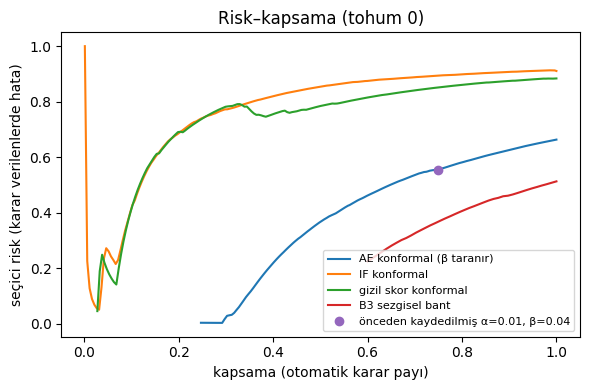

In [9]:
curves = {}
for model, label in [("ae", "AE konformal (β taranır)"), ("iforest", "IF konformal"), ("latent", "gizil skor konformal")]:
    ev_m = E.eval_set(P, S0, model)
    curves[label] = MT.risk_coverage_curve(ev_m["y_attack"], D0[f"{model}__p"], cfg.alpha)
ev = E.eval_set(P, S0, "ae"); h = C.heuristic_thresholds(ev["train"], *cfg.heuristic_k)
pts = []
for k in np.linspace(0, 0.4, 40):
    n_abs = int(k * len(ev["scores"]))
    tl = MT.band_for_abstention(ev["scores"], h["tau_H"], n_abs)
    pts.append(MT.selective_metrics(ev["y_attack"], C.decide_by_thresholds(ev["scores"], tl, h["tau_H"])))
curves["B3 sezgisel bant"] = pd.DataFrame(pts).sort_values("coverage")
ref = MT.selective_metrics(ev["y_attack"], D0["ae__d"])
PL.risk_coverage(curves, "Risk–kapsama (tohum 0)", RUN / "risk_coverage.png",
                 {f"önceden kaydedilmiş α={cfg.alpha}, β={cfg.beta}": (ref["coverage"], ref["selective_risk"])});

In [10]:
# AURC: güven = p-değerinin karar sınırına (log ölçekte) uzaklığı.
# Not: AURC her modelin KENDİ kararları ve sıralaması üzerinden hesaplanır; modeller farklı karar kümeleri
# ürettiği için modeller arası karşılaştırmaya uygun değildir (yalnızca bilgi amaçlı, birincil uç nokta değildir).
rows = []
for model in E.MODELS:
    ev_m = E.eval_set(P, S0, model); p_m = D0[f"{model}__p"]
    pred = p_m <= cfg.alpha
    conf = np.abs(np.log(p_m) - np.log(cfg.alpha))
    rows.append({"model": model, **MT.aurc(ev_m["y_attack"], conf, pred == ev_m["y_attack"])})
AU = pd.DataFrame(rows); AU.to_csv(RUN / "aurc_seed0.csv", index=False); AU.round(5)

,model,aurc,oracle_aurc,excess_aurc
0,ae,0.57629,0.29660,0.27969
1,iforest,0.75795,0.69455,0.06340
2,latent,0.81561,0.63334,0.18227


## Düşük p-değeri gerçekten 'saldırı' mı demek? (p-değeri aralığına göre güvenilirlik, tohum 0, AE)

,bin,n,attack_share,error_rate
0,"(-0.001, 0.001]",1661,0.9982,0.0018
1,"(0.001, 0.005]",3522,0.9974,0.0026
2,"(0.005, 0.01]",3923,0.9967,0.0033
3,"(0.01, 0.02]",6396,0.9955,0.0000
4,"(0.02, 0.05]",2832,0.9629,0.0000
5,"(0.05, 0.1]",513,0.6881,0.6881
6,"(0.1, 0.2]",7539,0.9593,0.9593
7,"(0.2, 0.5]",8553,0.8805,0.8805
8,"(0.5, 1.0]",1885,0.0976,0.0976


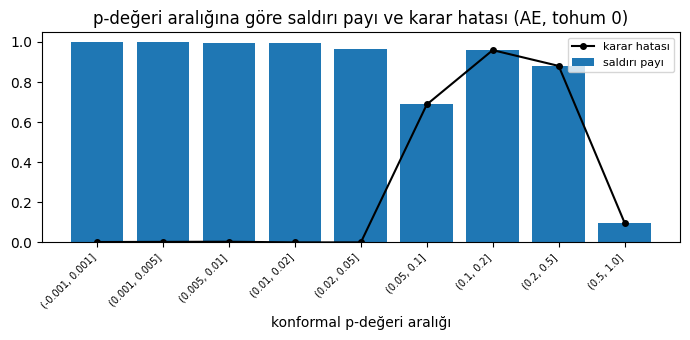

In [11]:
RB = MT.error_by_pvalue_bin(ev["y_attack"], D0["ae__p"], D0["ae__d"], cfg.pvalue_bins)
PL.reliability_bins(RB, "p-değeri aralığına göre saldırı payı ve karar hatası (AE, tohum 0)", RUN / "reliability_bins.png")
RB.round(4)

## E3 — Görülmemiş aileler: tespit edilen, ertelenen, kaçırılan (tohumlar üzerinden ortalama)
**Birincil recall** = çakışan (aynı vektörü normal etiketle de taşıyan) saldırılar *kaçırılmış* sayılarak hesaplanan kötümser değer.

In [12]:
fam_rows = []
for seed in SEEDS:
    S, Dd = E.load_scores(cfg, seed), decisions(seed)
    ev = E.eval_set(P, S, "ae")
    t = MT.per_family_table(ev["types"], Dd["ae__d"], GROUPS, collision=ev["collision"],
                            exclude_from_macro=EXCLUDE_MACRO); t["seed"] = seed; fam_rows.append(t)
FAM = pd.concat(fam_rows)
E3_COLS = ["anomaly_rate_collisions_as_missed", "anomaly_rate", "uncertain_rate", "normal_rate"]   # ilki = birincil
E3 = FAM.groupby(["group", "family"])[[c for c in E3_COLS if c in FAM]].agg(["mean", "std"]).round(4)
FAM.to_csv(RUN / "E3_per_family_all_seeds.csv", index=False); E3

anomaly_rate_collisions_as_missed         anomaly_rate         uncertain_rate         normal_rate        
                                                    mean     std         mean     std           mean     std        mean     std
group    family                                                                                                                 
held-out macro-average                            0.1935  0.0373       0.1944  0.0376         0.5777  0.0299      0.2280  0.0148
         mitm                                     0.0515  0.0050       0.0525  0.0050         0.3950  0.0376      0.5526  0.0360
         ransomware                               0.0105  0.0043       0.0121  0.0057         0.9815  0.0077      0.0065  0.0066
         xss                                      0.5185  0.1104       0.5185  0.1104         0.3567  0.0835      0.1248  0.0277
known    backdoor                                 0.1331  0.0039       0.1331  0.0039         0.8571  0.0039      0.0098  0.0000
         ddos                                     0.6476  0.0791       0.6478  0.0791         0.2709  0.0783      0.0813  0.0020
         dos                                      0.0332  0.0126       0.0337  0.0126         0.6087  0.0141      0.3577  0.0029
         injection                                0.0743  0.0114       0.0743  0.0114         0.1013  0.0111      0.8244  0.0006
         macro-average                            0.1701  0.0224       0.1702  0.0224         0.4733  0.0228      0.3565  0.0014
         password                                 0.0680  0.0303       0.0680  0.0303         0.0826  0.0296      0.8495  0.0026
         scanning                                 0.0642  0.0307       0.0645  0.0308         0.9192  0.0326      0.0163  0.0038
normal   macro-average                               NaN     NaN       0.0072  0.0010         0.0411  0.0017      0.9517  0.0014
         normal                                      NaN     NaN       0.0072  0.0010         0.0411  0.0017      0.9517  0.0014

## İkincil: tekrar ağırlıklandırmasına duyarlılık (satır ağırlıklı ve benzersiz vektör, tohum 0, AE)
Garanti benzersiz vektörler içindir; satır (akış) ağırlıklı oranlar ikincil olarak, ek bir 'kayma' (S0) gibi raporlanır.

In [13]:
ev = E.eval_set(P, S0, "ae"); d = D0["ae__d"]; w = ev["multiplicity"]
g = E.group_of(ev["types"], cfg)
rows = []
for grp in ["normal", "known", "held-out"]:
    m = g == grp
    rows.append({"grup": grp, "anomaly_benzersiz": np.mean(d[m] == C.ANOMALY),
                 "anomaly_satir_agirlikli": np.average(d[m] == C.ANOMALY, weights=w[m]),
                 "uncertain_benzersiz": np.mean(d[m] == C.UNCERTAIN),
                 "uncertain_satir_agirlikli": np.average(d[m] == C.UNCERTAIN, weights=w[m])})
MW = pd.DataFrame(rows); MW.to_csv(RUN / "multiplicity_weighted_seed0.csv", index=False); MW.round(4)

,grup,anomaly_benzersiz,anomaly_satir_agirlikli,uncertain_benzersiz,uncertain_satir_agirlikli
0,normal,0.0075,0.0051,0.0400,0.0203
1,known,0.1843,0.1453,0.2383,0.5642
2,held-out,0.4892,0.1475,0.3552,0.8060


## Normal/saldırı çakışmaları (aynı vektör iki etiketle görülmüş)
Bir normal ve bir saldırı kopyası tutulur; saldırı kopyası işaretlenir. Recall: (a) olduğu gibi, (b) çakışmalar hariç, (c) çakışan saldırılar kaçırılmış sayılarak. **(c) birincil (kötümser) değerdir.**

In [14]:
rows = []
for grp in ["known", "held-out"]:
    m = g == grp; c = ev["collision"] & m
    rec = np.mean(d[m] == C.ANOMALY)
    rec_excl = np.mean(d[m & ~ev["collision"]] == C.ANOMALY) if (m & ~ev["collision"]).any() else np.nan
    rec_pess = np.mean(np.where(ev["collision"][m], False, d[m] == C.ANOMALY))
    rows.append({"grup": grp, "çakışan_vektör": int(c.sum()), "recall": rec,
                 "recall_çakışmalar_hariç": rec_excl, "recall_çakışmalar_kaçmış (birincil)": rec_pess})
COL = pd.DataFrame(rows); COL.to_csv(RUN / "collisions_seed0.csv", index=False); COL.round(4)

,grup,çakışan_vektör,recall,recall_çakışmalar_hariç,recall_çakışmalar_kaçmış (birincil)
0,known,12,0.1843,0.1843,0.1842
1,held-out,15,0.4892,0.4897,0.4889


## Ara rapor özeti (profesör için)

In [15]:
val = pd.read_csv(FIG / "03_validity_E1.csv")
summary = {
    "yapilandirma": {"alpha": cfg.alpha, "beta": cfg.beta, "tohumlar": SEEDS, "gorulmeyecek_aileler": cfg.heldout_families},
    "E1_gecerlilik_tohum_ortalamasi": val.groupby(["model", "decision"])[["budget", "mean", "share_above_theory_q95"]].mean().round(5).reset_index().to_dict(orient="records"),
    "E2_eslestirilmis_kapsama": ST.round(5).to_dict(orient="records"),
    "B3_yanlis_alarm_10_tohum": B3F.drop(columns=["tohum"], errors="ignore").agg(["mean", "std"]).round(5).to_dict(),
    "katmanlama_10_tohum": TIER.groupby(["saldırılar", "yaygınlık", "rule"])[cols].mean().round(4).reset_index().to_dict(orient="records"),
    "E3_gorulmemis": FAM[FAM["group"] == "held-out"].groupby("family")[[c for c in E3_COLS if c in FAM]].mean().round(4).reset_index().to_dict(orient="records"),
    "profesor_metrikleri_tohum0": PROF.round(4).to_dict(orient="records"),
    "ortam": utils.environment_info(),
}
utils.save_json(summary, RUN / "midterm_summary.json")
import shutil
cfg.save(RUN / "config_used.json")
for f in ["data_file_info.json", "training_summary.json", "ae_selection.json", "environment.json"]:
    if (ART / f).exists():
        shutil.copy(ART / f, RUN / f)
shutil.copy(ART / "prepared" / "prepare_report.json", RUN / "prepare_report.json")
shutil.copytree(FIG, RUN / "figures", dirs_exist_ok=True)   # bu çalıştırmanın şekilleri/tabloları, ileride üzerine yazılmasın
print("Tüm sonuçlar kaydedildi (yapılandırma ve şekiller dahil):", RUN)
pd.DataFrame(summary["E3_gorulmemis"])

Tüm sonuçlar kaydedildi (yapılandırma ve şekiller dahil): /content/drive/MyDrive/TrustFed-TinyIDS-Final/runs/20261111-042106_midterm_phase4


,family,anomaly_rate_collisions_as_missed,anomaly_rate,uncertain_rate,normal_rate
0,macro-average,0.1935,0.1944,0.5777,0.2280
1,mitm,0.0515,0.0525,0.3950,0.5526
2,ransomware,0.0105,0.0121,0.9815,0.0065
3,xss,0.5185,0.5185,0.3567,0.1248


**Sonraki adım (final aşama):** `04b_uncertain_resolution`, ardından `F1_fl_teshis`, `F2_lofo`, `F3_asama5_9_on_tohum`.

In [16]:
# Colab: Drive'a yazılan tüm dosyaların kaydedildiğinden emin ol (oturumu kapatmadan önce mutlaka çalıştırın)
print("Kaydedilen ilerleme:", utils.progress(cfg))
if IN_COLAB:
    drive.flush_and_unmount()
    print("Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.")

Kaydedilen ilerleme: {'01_hazirlanan_veri': True, '02_tohumlar_tamam': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '02_oznitelik_karsilastirma_tohumlari': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '03_kararlar': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], '04b_host_eslesmesi': False}
Drive kaydedildi ve ayrıldı. Sonraki defter Drive'ı yeniden bağlar.
